# Alquiler frente al conjunto de precios de consumo

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"                       # carpeta en research/temas/
GRAFICA_ID = "evolucion-precios-alquiler-real"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Alquiler frente al conjunto de precios de consumo"  # `titulo` de la gráfica en config.json
DESDE = 1976                            # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"                 # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Índice real"                  # se completa con el año base en la transformación
CSV_FORMATO = "es"                      # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2                       # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = 100                        # línea horizontal de referencia en el valor base del índice
DIR_SALIDA = None                       # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Si el alquiler de vivienda se ha encarecido más o menos que el conjunto de los precios de consumo. No dice cuánto ha subido el alquiler: para eso está la gráfica `evolucion-precios-alquiler`, en términos nominales. Para cada área se divide el índice de alquileres del índice de precios de consumo (IPC) entre el IPC general de esa misma área, y el resultado se expresa con 100 en el primer año en que hay datos de todas las áreas (el año base figura en la unidad).

**Cómo se lee.** Un valor por encima de 100 indica que, desde el año base, los alquileres han subido más que el conjunto de los precios de consumo; por debajo de 100, que han subido menos. La gráfica compara **evoluciones**, no niveles: que dos áreas estén en el mismo valor no significa que el alquiler cueste lo mismo en ellas.

**Limitaciones.**
- El componente de alquiler del IPC mide la renta que pagan **todos los contratos vigentes**, no solo los que se firman cada año. Por eso reacciona más despacio que los precios de los contratos nuevos o de los anuncios.
- La UE-27 usa el índice armonizado de Eurostat (IPCA) y el resto de áreas el IPC nacional que publica la OCDE. Sus métodos son parecidos pero no idénticos.
- El índice no tiene en cuenta cambios en la renta de los hogares: para el peso del alquiler en la renta, véase la gráfica `esfuerzo-alquiler`.

## 2. Descarga

- **España, OCDE, EE. UU. y Canadá:** índice de alquileres (`RPI`) de los *Analytical house price indicators* de la OCDE y, como deflactor, el IPC general nacional (`CPI`, todos los bienes) del conjunto *Consumer price indices* de la OCDE.
- **UE-27:** IPCA anual de Eurostat (`prc_hicp_ainr`, clasificación ECOICOP v2): subclase 04.1 «alquileres efectivos de la vivienda» y, como deflactor, el índice general.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos, eurostat, oecd
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

AREAS_OCDE = {"ESP": "espana", "OECD": "ocde", "USA": "eeuu", "CAN": "canada"}
DF_ALQUILER = "OECD.ECO.MPD,DSD_AN_HOUSE_PRICES@DF_HOUSE_PRICES,1.0"
DF_IPC = "OECD.SDD.TPS,DSD_PRICES@DF_PRICES_ALL,1.0"
HICP = "prc_hicp_ainr"


def descargar():
    """Devuelve los índices nominales: {"alquiler": df, "ipc": df} y las fuentes de cada descarga."""
    alq_ocde, f_alq_ocde = oecd.get(DF_ALQUILER, "{AREA}.A.RPI.IX", areas=AREAS_OCDE, desde=DESDE)
    ipc_ocde, f_ipc_ocde = oecd.get(DF_IPC, "{AREA}.A.N.CPI.IX._T.N._Z", areas=AREAS_OCDE, desde=DESDE)
    ue = {"EU27_2020": "ue27"}
    alq_ue, f_alq_ue = eurostat.get(HICP, {"freq": "A", "unit": "INX_A_AVG", "coicop18": "CP041"}, geos=ue, desde=DESDE)
    ipc_ue, f_ipc_ue = eurostat.get(HICP, {"freq": "A", "unit": "INX_A_AVG", "coicop18": "TOTAL"}, geos=ue, desde=DESDE)
    indices = {
        "alquiler": pd.concat([alq_ocde, alq_ue], ignore_index=True),
        "ipc": pd.concat([ipc_ocde, ipc_ue], ignore_index=True),
    }
    return indices, [*f_alq_ocde, *f_ipc_ocde, *f_alq_ue, *f_ipc_ue]


indices, fuentes_descarga = descargar()
for nombre, d in indices.items():
    print(nombre, d.dropna().groupby("serie")["periodo"].agg(["min", "max"]).to_dict("index"))

alquiler {'canada': {'min': 1976, 'max': 2025}, 'eeuu': {'min': 1976, 'max': 2024}, 'espana': {'min': 1976, 'max': 2025}, 'ocde': {'min': 1976, 'max': 2025}, 'ue27': {'min': 2000, 'max': 2025}}
ipc {'canada': {'min': 1976, 'max': 2025}, 'eeuu': {'min': 1976, 'max': 2024}, 'espana': {'min': 1976, 'max': 2025}, 'ocde': {'min': 1976, 'max': 2024}, 'ue27': {'min': 2000, 'max': 2025}}


## 3. Transformación

Índice real = (alquiler / alquiler en el año base) / (IPC / IPC en el año base) × 100, calculado por separado en cada área con sus propios índices. El año base es el primer año en que todas las series tienen dato, para que todas partan del mismo punto; así tampoco importa la base con que publique cada fuente.

In [ ]:
ancho = {
    nombre: d.pivot(index="periodo", columns="serie", values="valor")
    for nombre, d in indices.items()
}
alq, ipc = ancho["alquiler"], ancho["ipc"].reindex(columns=ancho["alquiler"].columns)

# Año base: primer año con dato en todas las series que tienen alguno (skill investigar-tema)
con_datos = [s for s in alq.columns if (alq[s].notna() & ipc[s].notna()).any()]
completos = (alq[con_datos].notna() & ipc[con_datos].notna()).all(axis=1)
BASE = int(completos[completos].index.min())
UNIDAD = f"Índice real, {BASE} = 100 (alquiler del IPC deflactado por el IPC general)"

NOTAS = [
    f"Índice real: componente de alquiler de vivienda del índice de precios de consumo dividido por el índice general de precios de consumo de la misma área, con {BASE} = 100, el primer año con datos de todas las áreas. Por encima de 100, el alquiler ha subido más que el conjunto de precios desde {BASE}.",
    "España, OCDE, EE. UU. y Canadá: índice de alquileres (RPI) de los Analytical house price indicators de la OCDE, que es el componente de alquiler del IPC nacional enlazado por la OCDE entre cambios de base, deflactado con el IPC general nacional publicado por la OCDE (Consumer price indices, COICOP 1999). En España, el IPC es el del INE.",
    "UE-27: IPCA anual de Eurostat (prc_hicp_ainr, ECOICOP v2), subclase 04.1 «alquileres efectivos de la vivienda» dividida por el IPCA general. Agregado de composición actual (EU27_2020). El IPCA y los IPC nacionales usan métodos parecidos pero no idénticos.",
    "EE. UU., Canadá y la OCDE no tienen IPCA; se deflacta con su IPC nacional, el mismo marco que el índice de alquileres de la OCDE (METODOLOGIA §2.4).",
    "OCDE: cociente entre el índice agregado de alquileres y el IPC agregado de la OCDE.",
    "El componente de alquiler del IPC mide la renta de todos los contratos vigentes, no solo la de los contratos nuevos, por lo que reacciona más despacio que los precios de los contratos que se firman cada año.",
]

real = (alq / alq.loc[BASE]) / (ipc / ipc.loc[BASE]) * 100

df = real.reset_index().melt(id_vars="periodo", var_name="serie", value_name="valor")[["serie", "periodo", "valor"]]

# Series que terminan antes que las demás: qué índice falta el año siguiente
ultimo_global = max(real[s].last_valid_index() for s in real.columns)
for s in real.columns:
    ult = real[s].last_valid_index()
    if ult < ultimo_global:
        faltan = [
            nombre
            for nombre, tabla in (("del índice de alquileres", alq), ("del índice general de precios", ipc))
            if pd.isna(tabla[s].get(ult + 1))
        ]
        NOTAS.append(f"{s}: el último año con dato es {ult} porque la fuente aún no ha publicado el dato anual de {ult + 1} {' ni '.join(faltan)}.")

# Una fuente por serie: numerador y deflactor vienen del mismo organismo
def fuente(serie, organismo, codigo, url):
    fecha = max(f.fecha_consulta for f in fuentes_descarga if f.serie == serie)
    return FuenteMeta(serie, organismo, codigo, url, fecha)

fuentes = [
    fuente(s, oecd.ORGANISMO, "DSD_AN_HOUSE_PRICES@DF_HOUSE_PRICES (RPI) / DSD_PRICES@DF_PRICES_ALL (CPI, total)", oecd.URL_EXPLORER)
    for s in AREAS_OCDE.values()
] + [fuente("ue27", eurostat.ORGANISMO, f"{HICP} (CP041 / TOTAL)", eurostat.URL_DATABROWSER.format(dataset=HICP))]

## 4. Visualización

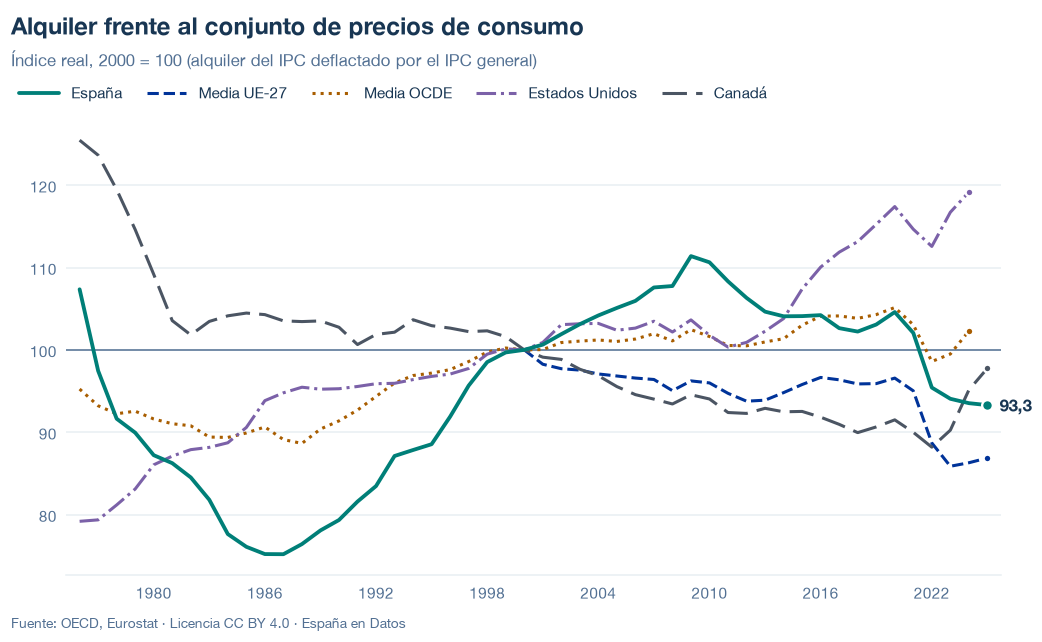

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/evolucion-precios-alquiler-real.json y data/evolucion-precios-alquiler-real.csv


## 6. Fuentes, notas y licencia

**Fuentes:**
- OCDE, *Analytical house price indicators* (`OECD.ECO.MPD,DSD_AN_HOUSE_PRICES@DF_HOUSE_PRICES`), medida `RPI` (alquileres).
- OCDE, *Consumer price indices* (`OECD.SDD.TPS,DSD_PRICES@DF_PRICES_ALL`), IPC nacional, todos los bienes.
- Eurostat, IPCA anual (`prc_hicp_ainr`), subclase 04.1 y total.

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Notas:** están en `notas` del JSON e incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.